# CS2 AK-47 Price Estimator
Reads Steam Market price history CSVs from `items/`, takes each AK-47 skin's latest price,
and trains a Random Forest to estimate a skin's price from its **name, wear and StatTrak status**.
Run the cells top to bottom.

In [36]:
import os
import re
import urllib.parse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

ITEMS_DIR = "items"
WEAPON = "AK-47"

## Parsing skin names
`parse_steam_name` splits a Steam Market name into the model's inputs.
`"StatTrak™ AK-47 | Aquamarine Revenge (Battle-Scarred)"` becomes `("Aquamarine Revenge", "Battle-Scarred", 1)`.
It returns `None` for anything that isn't an AK-47, so those files get skipped.

In [37]:
def parse_steam_name(market_name, weapon=WEAPON):
    """
    "StatTrak™ AK-47 | Aquamarine Revenge (Battle-Scarred)"
      -> ("Aquamarine Revenge", "Battle-Scarred", 1)
    Returns None if the name isn't for the given weapon or can't be parsed.
    """
    if weapon not in market_name:
        return None

    try:
        skin_part = market_name.split(" | ")[1]
    except IndexError:
        return None

    skin_name = skin_part.split(" (")[0].strip()
    wear_match = re.search(r"\((.*?)\)", skin_part)
    wear = wear_match.group(1) if wear_match else "Vanilla"
    is_stattrak = int("StatTrak" in market_name)

    return skin_name, wear, is_stattrak

## Loading the data
`load_dataset` goes through every CSV in `items/`, decodes the filename, parses it, and keeps the
**most recent price** for each skin. The result is one row per skin.

In [38]:
def load_dataset(folder=ITEMS_DIR):
    """Read every matching CSV in `folder` and return one row per skin with its latest price."""
    rows = []

    for filename in os.listdir(folder):
        if not filename.endswith(".csv"):
            continue

        # "AK-47%20%7C%20...csv" -> "AK-47 | ..."
        market_name = urllib.parse.unquote(filename).removesuffix(".csv")
        stats = parse_steam_name(market_name)
        if stats is None:
            continue

        try:
            history = pd.read_csv(os.path.join(folder, filename))
            # Sort by time so "latest" is really the latest
            latest_price = history.sort_values("unix timestamp")["price"].iloc[-1]
        except Exception as e:
            print(f"Skipping {filename}: {e}")
            continue

        skin_name, wear, is_stattrak = stats
        rows.append({
            "skin_name": skin_name,
            "wear_condition": wear,
            "is_stattrak": is_stattrak,
            "price_usd": latest_price,
        })

    return pd.DataFrame(rows)

## Preparing the data
Splits the table into inputs (`X`) and the price to predict (`y`), then sets up the encoder that turns
text like `"Battle-Scarred"` into 0/1 columns the model can read.

In [39]:
df = load_dataset()
print(f"Loaded {len(df)} {WEAPON} skins")
df.head()

X = df.drop(columns=["price_usd"])
y = df["price_usd"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["skin_name", "wear_condition"]),
    ],
    remainder="passthrough",
)

Loaded 428 AK-47 skins


## The model
A Random Forest (200 decision trees whose predictions are averaged). It trains on `log(price)` so a few very
expensive skins don't dominate, and converts predictions back to dollars automatically.

In [40]:
model = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(n_estimators=200, random_state=42)),
    ]),
    func=np.log1p,
    inverse_func=np.expm1,
)

## Training and testing
Holds back 20% of the skins as a test set, trains on the other 80%, then scores the model on the held-back skins.
- **MAE**: average miss in dollars
- **R^2**: 1.0 is perfect, 0 is no better than guessing the average price

In [41]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print(f"Mean absolute error: ${mean_absolute_error(y_test, predictions):.2f}")
print(f"R²: {r2_score(y_test, predictions):.2f}")

Mean absolute error: $116.51
R²: 0.51


In [52]:
# Change these values to whatever skin you want to check!
new_skin = pd.DataFrame({
    'skin_name': ['Phantom Disruptor'],
    'wear_condition': ['Factory New'],
    'is_stattrak': [0] # 0 for normal, 1 for StatTrak
})

predicted_price = model.predict(new_skin)
print(f"AI Predicted Market Price: ${predicted_price[0]:.2f}")

AI Predicted Market Price: $15.06


## Listing available skins
Prints every skin name that has a CSV in `items/`, so you can copy exact names for the plot below.

In [44]:
names = sorted(urllib.parse.unquote(f).removesuffix(".csv")
               for f in os.listdir(ITEMS_DIR) if f.endswith(".csv"))
print(len(names))
print("\n".join(names))

22495
'Blueberries' Buckshot | NSWC SEAL
'Medium Rare' Crasswater | Guerrilla Warfare
'The Doctor' Romanov | Sabre
'Two Times' McCoy | TACP Cavalry
'Two Times' McCoy | USAF TACP
10 Year Birthday Sticker Capsule
1st Lieutenant Farlow | SWAT
2020 RMR Challengers
2020 RMR Contenders
2020 RMR Legends
2021 Community Sticker Capsule
3rd Commando Company | KSK
AK-47 | Aquamarine Revenge (Battle-Scarred)
AK-47 | Aquamarine Revenge (Factory New)
AK-47 | Aquamarine Revenge (Field-Tested)
AK-47 | Aquamarine Revenge (Minimal Wear)
AK-47 | Aquamarine Revenge (Well-Worn)
AK-47 | Asiimov (Battle-Scarred)
AK-47 | Asiimov (Factory New)
AK-47 | Asiimov (Field-Tested)
AK-47 | Asiimov (Minimal Wear)
AK-47 | Asiimov (Well-Worn)
AK-47 | Baroque Purple (Battle-Scarred)
AK-47 | Baroque Purple (Factory New)
AK-47 | Baroque Purple (Field-Tested)
AK-47 | Baroque Purple (Minimal Wear)
AK-47 | Baroque Purple (Well-Worn)
AK-47 | Black Laminate (Battle-Scarred)
AK-47 | Black Laminate (Factory New)
AK-47 | Black Lami

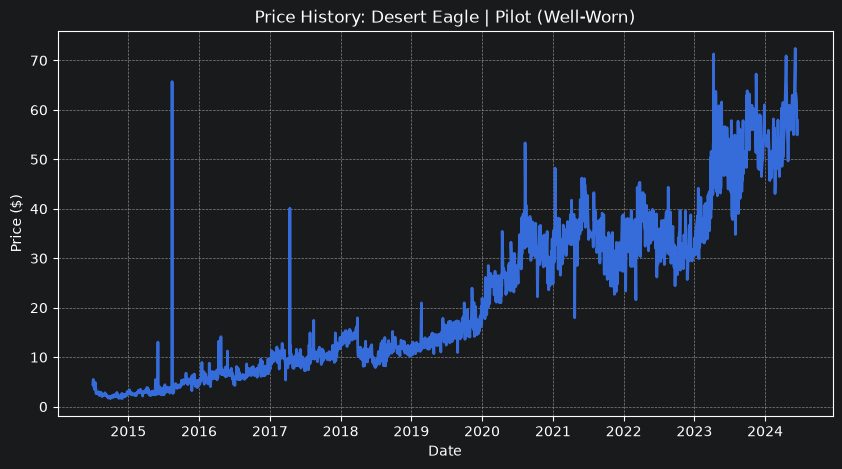

In [48]:
def plot_price_history(market_name, folder=ITEMS_DIR):
    # Filenames on disk are URL-encoded
    path = os.path.join(folder, urllib.parse.quote(market_name, safe="()") + ".csv")
    history = pd.read_csv(path)
    history["datetime"] = pd.to_datetime(history["unix timestamp"], unit="s")

    plt.figure(figsize=(10, 5))
    plt.plot(history["datetime"], history["price"], linewidth=2)
    plt.title(f"Price History: {market_name}")
    plt.xlabel("Date")
    plt.ylabel("Price ($)")
    plt.grid(True, linestyle="--", alpha=0.7)
    plt.show()


plot_price_history("Desert Eagle | Pilot (Well-Worn)")